# 02. Olhando sem rótulo (aprendizado não supervisionado)

**Pergunta:** sem dizer ao algoritmo o que é spam, os e-mails se separam sozinhos?

Quatro olhares, todos sem usar o rótulo para aprender (o rótulo só entra para *avaliar*):
1. **SVD** (análise semântica latente): comprime as 3000 colunas em poucas direções e projeta em 2D.
2. **Agrupamento** (K-means e hierárquico de Ward): os grupos encontrados coincidem com spam × e-mail real? (ARI)
3. **Tópicos** (NMF): quais assuntos existem na caixa?
4. **Detecção de anomalia**: treinar só com e-mails reais e tratar spam como "o que foge do normal".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score, average_precision_score, matthews_corrcoef, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.svm import OneClassSVM
from sklearn.linear_model import LogisticRegression

from spamfilter import dados, graficos, representacao, saidas
from spamfilter.dados import SEED

base = dados.carregar()
y = base.y
T = representacao.tfidf().fit_transform(base.X)          # TF-IDF com log (não usa o rótulo)

## 1. SVD: o mapa da caixa de e-mail em 2D

variância explicada: 2 direções 6.5% | 10 direções 18.2% | 100 direções 44.6%
direção 2: correlação com spam -0.25 | +: ['hpl', 'xls', 'hplno', 'file', 'attached', 'hplo'] | -: ['the', 'and', 'you', 'his', 'our', 'this']
direção 3: correlação com spam +0.11 | +: ['xls', 'hplno', 'file', 'attached', 'see', 'att'] | -: ['teco', 'tap', 'enron', 'actuals', 'actual', 'iferc']
direção 4: correlação com spam -0.24 | +: ['enron', 'hpl', 'tap', 'teco', 'actual', 'actuals'] | -: ['ect', 'http', 'you', 'calpine', 'doc', 'alpine']


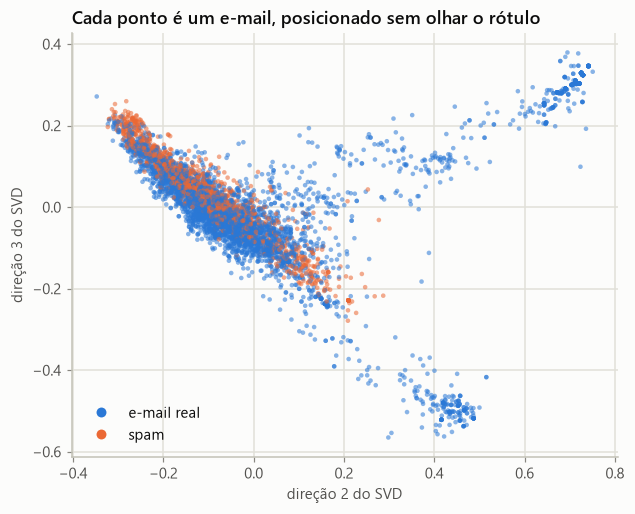

In [2]:
svd = TruncatedSVD(100, random_state=SEED).fit(T)
Z = Normalizer().fit_transform(svd.transform(T))          # LSA: direções semânticas, normalizadas
var = svd.explained_variance_ratio_
print(f"variância explicada: 2 direções {var[:2].sum():.1%} | 10 direções {var[:10].sum():.1%} | 100 direções {var.sum():.1%}")
vocab = np.array(base.vocab); longas = np.array([len(w) >= 3 for w in vocab])
direcoes = []
for i in range(1, 4):
    c = svd.components_[i]; o = np.argsort(c)
    pos = [str(w) for w in vocab[o[::-1]] if len(w) >= 3][:6]; neg = [str(w) for w in vocab[o] if len(w) >= 3][:6]
    r = np.corrcoef(Z[:, i], y)[0, 1]
    direcoes.append(dict(direcao=i + 1, correlacao_com_spam=r, lado_positivo=pos, lado_negativo=neg))
    print(f"direção {i + 1}: correlação com spam {r:+.2f} | +: {pos} | -: {neg}")

# a 1ª direção do SVD sem centralizar é o "tamanho médio"; as direções 2 e 3 carregam o assunto
x2, y2 = Z[:, 1], Z[:, 2]
fig, ax = plt.subplots(figsize=(6.4, 5))
ordem = np.random.default_rng(SEED).permutation(base.n)
ax.scatter(x2[ordem], y2[ordem], s=9, c=[graficos.CLASSE[c] for c in y[ordem]], alpha=0.55, linewidths=0)
ax.set_xlabel("direção 2 do SVD"); ax.set_ylabel("direção 3 do SVD")
ax.set_title("Cada ponto é um e-mail, posicionado sem olhar o rótulo")
graficos.legenda_classes(ax, loc="lower left")
graficos.mostrar(fig, "02_svd_2d")

## 2. Agrupamento: os grupos coincidem com o rótulo?
ARI (*Adjusted Rand Index*): 1 = os grupos coincidem com spam × e-mail real; 0 = coincidência ao acaso.

 k    ari  silhueta  pureza
 2 -0.070     0.187   0.710
 3 -0.016     0.075   0.710
 4  0.142     0.063   0.798
 5  0.125     0.077   0.797
 6  0.099     0.084   0.759
 7  0.157     0.072   0.833
 8  0.129     0.076   0.855
 9  0.128     0.082   0.856
10  0.081     0.092   0.810



K-means (k=2) ARI -0.070 | hierárquico de Ward (2 grupos) ARI -0.071 | Ward com 8 grupos: pureza 87.4%


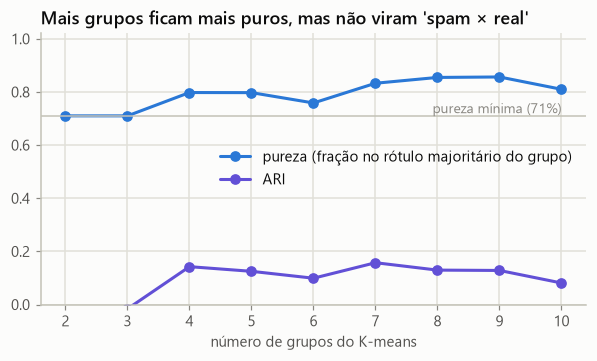

In [3]:
linhas = []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    pureza = pd.crosstab(km.labels_, y).max(axis=1).sum() / base.n
    linhas.append(dict(k=k, ari=adjusted_rand_score(y, km.labels_), silhueta=silhouette_score(Z, km.labels_, sample_size=2000, random_state=SEED),
                       pureza=pureza))
KM = pd.DataFrame(linhas)
print(KM.round(3).to_string(index=False))
kmeans_ari = float(KM.loc[KM.k == 2, "ari"].iloc[0])

ward = AgglomerativeClustering(2, linkage="ward").fit(Z)
hierarquico_ari = adjusted_rand_score(y, ward.labels_)
ward8 = AgglomerativeClustering(8, linkage="ward").fit(Z)
print(f"\nK-means (k=2) ARI {kmeans_ari:.3f} | hierárquico de Ward (2 grupos) ARI {hierarquico_ari:.3f} | "
      f"Ward com 8 grupos: pureza {pd.crosstab(ward8.labels_, y).max(axis=1).sum() / base.n:.1%}")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(KM.k, KM.pureza, marker="o", ms=6, color=graficos.CATEGORICA[0], label="pureza (fração no rótulo majoritário do grupo)")
ax.plot(KM.k, KM.ari, marker="o", ms=6, color=graficos.CATEGORICA[6], label="ARI")
ax.axhline((y == 0).mean(), color=graficos.EIXO, lw=1); ax.text(10, (y == 0).mean() + 0.01, "pureza mínima (71%)", ha="right", color=graficos.TINTA_MUDA, fontsize=9)
ax.set_xlabel("número de grupos do K-means"); ax.set_ylim(0, 1.02)
ax.set_title("Mais grupos ficam mais puros, mas não viram 'spam × real'"); ax.legend(loc="center right")
graficos.mostrar(fig, "02_kmeans")

## 3. Tópicos: do que falam os e-mails (NMF)

In [4]:
Tl = T[:, longas]                                          # só palavras com 3+ letras (as letras soltas viram ruído)
nmf = NMF(8, init="nndsvda", random_state=SEED, max_iter=400).fit(Tl)
W = nmf.transform(Tl); topico = W.argmax(1)
vl = vocab[longas]; topicos = []
for t in range(8):
    palavras = [str(w) for w in vl[np.argsort(-nmf.components_[t])[:8]]]
    n = int((topico == t).sum()); fs = float(y[topico == t].mean()) if n else np.nan
    topicos.append(dict(topico=t + 1, palavras=palavras, n_emails=n, fracao_spam=fs))
TOP = pd.DataFrame(topicos).sort_values("fracao_spam", ascending=False)
for _, r in TOP.iterrows():
    print(f"tópico {r.topico}: {r.n_emails:5d} e-mails | {r.fracao_spam:6.1%} spam | {', '.join(r.palavras)}")

tópico 4:  2220 e-mails |  65.2% spam | our, you, your, and, the, com, pro, est
tópico 8:   625 e-mails |   4.2% spam | enron, hou, corp, subject, ward, forwarded, forward, war
tópico 5:   208 e-mails |   3.8% spam | eastrans, deliver, deliveries, east, live, mmbtu, btu, del
tópico 7:   152 e-mails |   3.3% spam | calpine, alpine, nomination, daily, nat, min, gas, nom
tópico 1:  1274 e-mails |   0.8% spam | deal, the, meter, met, aren, daren, are, hanks
tópico 2:   387 e-mails |   0.8% spam | xls, hpl, hplno, file, attached, see, hplo, att
tópico 3:   209 e-mails |   0.0% spam | teco, tap, hpl, enron, actuals, actual, iferc, ferc
tópico 6:    97 e-mails |   0.0% spam | utilities, texas, tie, actual, jones, flow, enserch, nom


## 4. Spam como anomalia: treinar só com e-mails reais
Cenário realista quando não há spams rotulados. Validação cruzada por grupo (5 folds); o modelo vê só os e-mails
reais do treino; o limiar marca como spam o que for mais estranho que 95% dos e-mails reais do treino.
Comparação: a Regressão Logística supervisionada nas mesmas divisões.

In [5]:
def avaliar_anomalia(criar):
    pr, mcc = [], []
    for tr, te in dados.divisoes(y, base.g, SEED):
        tr_real = tr[y[tr] == 0]
        m = make_pipeline(TruncatedSVD(100, random_state=SEED), Normalizer(), criar()).fit(T[tr_real])
        s_tr, s_te = -m.decision_function(T[tr_real]), -m.decision_function(T[te])   # maior = mais anômalo
        lim = np.quantile(s_tr, 0.95)
        pr.append(average_precision_score(y[te], s_te)); mcc.append(matthews_corrcoef(y[te], s_te > lim))
    return float(np.mean(pr)), float(np.mean(mcc))

iso_pr, iso_mcc = avaliar_anomalia(lambda: IsolationForest(n_estimators=300, random_state=SEED))
ocs_pr, ocs_mcc = avaliar_anomalia(lambda: OneClassSVM(nu=0.05, gamma="scale"))

Os dois detectores clássicos ficam **abaixo do acaso** (PR-AUC < 0,29, a fração de spam): o spam parece *menos*
estranho que os e-mails reais. Motivo: projetado nas direções aprendidas só com e-mails reais, o spam cai perto da
origem (ele usa outras palavras), e um ponto perto do centro não parece isolado. O que distingue o spam é estar
**fora** do espaço dos e-mails reais. A medida certa é então o **erro de reconstrução**: quanto do e-mail as
100 direções dos e-mails reais não conseguem explicar (k = 100 fixado antes, a mesma dimensão do mapa).

fração de spam (PR-AUC de quem sorteia): 0.290
                                        metodo  pr_auc    mcc
           Isolation Forest (só e-mails reais)   0.184 -0.074
              One-Class SVM (só e-mails reais)   0.168 -0.106
Erro de reconstrução do SVD (só e-mails reais)   0.802  0.635
                 Reg. Logística supervisionada   0.996  0.961


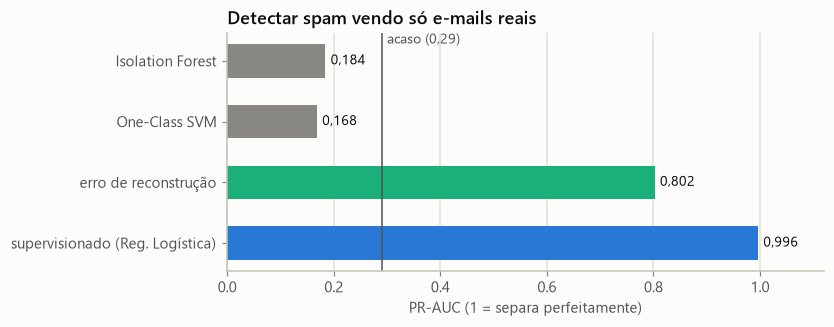

In [6]:
def avaliar_reconstrucao(k=100):
    pr, mcc = [], []
    for tr, te in dados.divisoes(y, base.g, SEED):
        tr_real = tr[y[tr] == 0]
        svd_r = TruncatedSVD(k, random_state=SEED).fit(T[tr_real])
        def erro(M):
            R = svd_r.transform(M) @ svd_r.components_
            return np.asarray(M.multiply(M).sum(1)).ravel() - 2 * np.asarray(M.multiply(R).sum(1)).ravel() + (R ** 2).sum(1)
        s_tr, s_te = erro(T[tr_real]), erro(T[te]); lim = np.quantile(s_tr, 0.95)
        pr.append(average_precision_score(y[te], s_te)); mcc.append(matthews_corrcoef(y[te], s_te > lim))
    return float(np.mean(pr)), float(np.mean(mcc))

rec_pr, rec_mcc = avaliar_reconstrucao(100)
sup_pr, sup_mcc = [], []
for tr, te in dados.divisoes(y, base.g, SEED):
    m = make_pipeline(representacao.tfidf(), LogisticRegression(C=10, max_iter=3000, class_weight="balanced")).fit(base.X[tr], y[tr])
    sup_pr.append(average_precision_score(y[te], m.predict_proba(base.X[te])[:, 1])); sup_mcc.append(matthews_corrcoef(y[te], m.predict(base.X[te])))
ANOM = pd.DataFrame([dict(metodo="Isolation Forest (só e-mails reais)", pr_auc=iso_pr, mcc=iso_mcc),
                     dict(metodo="One-Class SVM (só e-mails reais)", pr_auc=ocs_pr, mcc=ocs_mcc),
                     dict(metodo="Erro de reconstrução do SVD (só e-mails reais)", pr_auc=rec_pr, mcc=rec_mcc),
                     dict(metodo="Reg. Logística supervisionada", pr_auc=np.mean(sup_pr), mcc=np.mean(sup_mcc))])
print(f"fração de spam (PR-AUC de quem sorteia): {y.mean():.3f}")
print(ANOM.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 2.8))
cores = [graficos.TINTA_MUDA, graficos.TINTA_MUDA, graficos.CATEGORICA[2], graficos.CATEGORICA[0]]
ax.barh(range(len(ANOM)), ANOM.pr_auc, height=0.55, color=cores)
ax.set_yticks(range(len(ANOM)), ["Isolation Forest", "One-Class SVM", "erro de reconstrução", "supervisionado (Reg. Logística)"])
ax.axvline(y.mean(), color=graficos.TINTA_2, lw=1); ax.text(y.mean() + 0.01, -0.45, "acaso (0,29)", color=graficos.TINTA_2, fontsize=9, va="top")
for i, v in enumerate(ANOM.pr_auc):
    ax.text(v + 0.01, i, f"{v:.3f}".replace(".", ","), va="center", color=graficos.TINTA, fontsize=9)
ax.set_xlim(0, 1.12); ax.grid(axis="y", visible=False); ax.invert_yaxis()
ax.set_xlabel("PR-AUC (1 = separa perfeitamente)"); ax.set_title("Detectar spam vendo só e-mails reais")
graficos.mostrar(fig, "02_anomalia")

**Leitura.** A estrutura existe (há tópicos quase só de spam e outros quase só de e-mail real), mas o agrupamento
não a encontra sozinho como "spam × real": os grupos naturais são *assuntos*, e a caixa tem vários assuntos de
trabalho. Sem rótulo, a melhor pista é "este e-mail não se parece com os meus e-mails reais" (erro de
reconstrução), que já separa bem, mas o supervisionado fica muito à frente: o rótulo é o que vira filtro.

In [7]:
pts = np.column_stack([x2, y2, y])[ordem]
saidas.gravar("02_nao_supervisionado", {
    "nao_supervisionado": dict(
        variancia_svd={"2": float(var[:2].sum()), "10": float(var[:10].sum()), "100": float(var.sum())},
        direcoes=direcoes, svd2d=[[round(float(a), 4), round(float(b), 4), int(c)] for a, b, c in pts],
        kmeans=KM, kmeans_ari=kmeans_ari, hierarquico_ari=float(hierarquico_ari),
        nmf_topicos=TOP, anomalia=ANOM,
        anomalia_so_email_real=dict(isolation_forest_mcc=iso_mcc, one_class_svm_mcc=ocs_mcc,
                                    isolation_forest_pr_auc=iso_pr, one_class_svm_pr_auc=ocs_pr,
                                    reconstrucao_mcc=rec_mcc, reconstrucao_pr_auc=rec_pr, fracao_spam=float(y.mean()),
                                    supervisionado_mcc=float(np.mean(sup_mcc)), supervisionado_pr_auc=float(np.mean(sup_pr)))),
}, fonte="scripts/02_exploracao_nao_supervisionada.py")
print("gravado: resultados/02_nao_supervisionado.json")

gravado: resultados/02_nao_supervisionado.json
